In [10]:
import geopandas as gpd
import pandas as pd
import requests
import os
from shapely.geometry import Polygon

In [11]:
data_klien = [
    # Terdampak (17 Daerah)
    {"kabkot": "TAPANULI TENGAH", "terdampak": 1, "lat": 1.90, "lon": 98.60},
    {"kabkot": "TAPANULI UTARA", "terdampak": 1, "lat": 2.00, "lon": 99.00},
    {"kabkot": "TAPANULI SELATAN", "terdampak": 1, "lat": 1.50, "lon": 99.30},
    {"kabkot": "NIAS", "terdampak": 1, "lat": 1.10, "lon": 97.60},
    {"kabkot": "LANGKAT", "terdampak": 1, "lat": 3.60, "lon": 98.20},
    {"kabkot": "DELI SERDANG", "terdampak": 1, "lat": 3.40, "lon": 98.70}, # Tabel: Deli Serang
    {"kabkot": "ASAHAN", "terdampak": 1, "lat": 2.90, "lon": 99.60},
    {"kabkot": "MANDAILING NATAL", "terdampak": 1, "lat": 0.80, "lon": 99.50},
    {"kabkot": "PAKPAK BARAT", "terdampak": 1, "lat": 2.50, "lon": 98.30},
    {"kabkot": "HUMBANG HASUNDUTAN", "terdampak": 1, "lat": 2.30, "lon": 98.60},
    {"kabkot": "SERDANG BEDAGAI", "terdampak": 1, "lat": 3.40, "lon": 99.10},
    {"kabkot": "BATU BARA", "terdampak": 1, "lat": 3.10, "lon": 99.50},
    {"kabkot": "KOTA MEDAN", "terdampak": 1, "lat": 3.60, "lon": 98.67},
    {"kabkot": "KOTA SIBOLGA", "terdampak": 1, "lat": 1.74, "lon": 98.78},
    {"kabkot": "KOTA BINJAI", "terdampak": 1, "lat": 3.60, "lon": 98.48},
    {"kabkot": "KOTA TEBING TINGGI", "terdampak": 1, "lat": 3.32, "lon": 99.16},
    {"kabkot": "KOTA PADANG SIDEMPUAN", "terdampak": 1, "lat": 1.37, "lon": 99.27},

    # Tidak Terdampak (16 Daerah)
    {"kabkot": "KARO", "terdampak": 0, "lat": 3.10, "lon": 98.30},
    {"kabkot": "SIMALUNGUN", "terdampak": 0, "lat": 2.90, "lon": 99.00},
    {"kabkot": "LABUHAN BATU", "terdampak": 0, "lat": 2.30, "lon": 99.80},
    {"kabkot": "DAIRI", "terdampak": 0, "lat": 2.70, "lon": 98.30},
    {"kabkot": "TOBA SAMOSIR", "terdampak": 0, "lat": 2.40, "lon": 99.10},
    {"kabkot": "NIAS SELATAN", "terdampak": 0, "lat": 0.50, "lon": 97.80},
    {"kabkot": "SAMOSIR", "terdampak": 0, "lat": 2.60, "lon": 98.70},
    {"kabkot": "PADANG LAWAS UTARA", "terdampak": 0, "lat": 1.40, "lon": 99.60},
    {"kabkot": "PADANG LAWAS", "terdampak": 0, "lat": 1.10, "lon": 99.80},
    {"kabkot": "LABUHANBATU SELATAN", "terdampak": 0, "lat": 1.90, "lon": 100.10},
    {"kabkot": "LABUHANBATU UTARA", "terdampak": 0, "lat": 2.30, "lon": 99.60},
    {"kabkot": "NIAS UTARA", "terdampak": 0, "lat": 1.30, "lon": 97.30},
    {"kabkot": "NIAS BARAT", "terdampak": 0, "lat": 1.00, "lon": 97.50},
    {"kabkot": "KOTA PEMATANG SIANTAR", "terdampak": 0, "lat": 2.95, "lon": 99.06},
    {"kabkot": "KOTA TANJUNG BALAI", "terdampak": 0, "lat": 2.96, "lon": 99.80},
    {"kabkot": "KOTA GUNUNGSITOLI", "terdampak": 0, "lat": 1.28, "lon": 97.61}
]

df = pd.DataFrame(data_klien)

In [12]:
geojson_local = "sumut.geojson"
gdf = None

if os.path.exists(geojson_local):
    print(f"Membaca peta geometri asli dari '{geojson_local}'...")
    gdf_raw = gpd.read_file(geojson_local)

    # Matching nama kabupaten
    def match_status(nama):
        n_clean = str(nama).upper().replace("KABUPATEN", "").replace("KOTA", "").strip()
        for _, row in df.iterrows():
            k_clean = row['kabkot'].replace("KABUPATEN", "").replace("KOTA", "").strip()
            if k_clean in n_clean or n_clean in k_clean:
                return row['terdampak']
        return 0

    col_name = [c for c in ['WADMKK', 'namobj', 'description', 'name'] if c in gdf_raw.columns][0]
    gdf_raw['WADMKK'] = gdf_raw[col_name]
    gdf_raw['terdampak'] = gdf_raw[col_name].apply(match_status)
    gdf = gdf_raw[['WADMKK', 'terdampak', 'geometry']].copy()
else:
    print("File GeoJSON lokal tidak ditemukan. Membuat Shapefile mandiri berbasis koordinat batas...")
    geoms = []
    for _, row in df.iterrows():
        lat, lon = row['lat'], row['lon']
        d = 0.12  # Ukuran Polygon
        poly = Polygon([
            (lon - d, lat - d),
            (lon + d, lat - d),
            (lon + d, lat + d),
            (lon - d, lat + d)
        ])
        geoms.append(poly)

    gdf = gpd.GeoDataFrame(
        df[['kabkot', 'terdampak']].rename(columns={'kabkot': 'WADMKK'}),
        geometry=geoms,
        crs="EPSG:4326"
    )

File GeoJSON lokal tidak ditemukan. Membuat Shapefile mandiri berbasis koordinat batas...


In [13]:
output_shp = "Sumut_Terdampak_2025.shp"
gdf.to_file(output_shp)
print(f"-> BERHASIL: File Shapefile '{output_shp}' telah dibuat!")

-> BERHASIL: File Shapefile 'Sumut_Terdampak_2025.shp' telah dibuat!


-> BERHASIL: Preview gambar 'peta_preview_python.png' tersimpan.


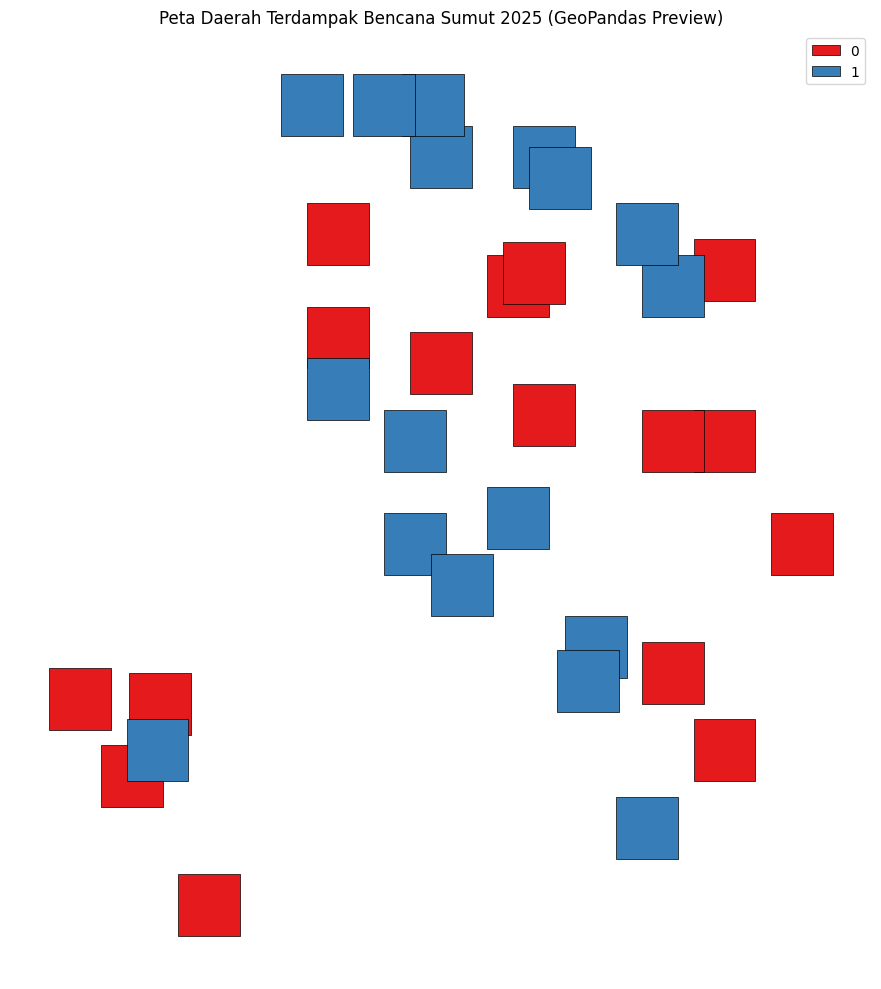

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
gdf.plot(
    column='terdampak',
    categorical=True,
    cmap='Set1',
    legend=True,
    ax=ax,
    edgecolor='black',
    linewidth=0.5
)
plt.title("Peta Daerah Terdampak Bencana Sumut 2025 (GeoPandas Preview)")
plt.axis('off')
plt.tight_layout()
plt.savefig("peta_preview_python.png", dpi=300)
print("-> BERHASIL: Preview gambar 'peta_preview_python.png' tersimpan.")